# Assignment 4: DBSCAN and BIRCH Clustering – Wholesale Customers

## Introduction
In this assignment I apply two clustering algorithms, DBSCAN and BIRCH, to the Wholesale Customers dataset from the UCI Machine Learning Repository (Cardoso, 2014). The dataset contains the annual spending of clients of a wholesale distributor in Portugal, measured in monetary units (m.u.), across product categories such as fresh food, milk, grocery, frozen food, detergents and paper, and delicatessen. It also includes each client's channel (Horeca: hotel/restaurant/café, or Retail) and region.

My goal is to group clients by their spending patterns and see how each algorithm behaves, and how its parameters change the results.

My steps:
- Explain how DBSCAN and BIRCH work
- Load and explore the dataset
- Select and preprocess the spending features
- Apply DBSCAN, tune eps and min_samples, and visualize the results
- Apply BIRCH, tune n_clusters, and visualize the results
- Discuss the impact of the parameters and the strengths and limitations of each algorithm
- Write a summary of my findings


## 1. Introduction to DBSCAN and BIRCH

 ### DBSCAN (Density-Based Spatial Clustering of Applications with Noise)
DBSCAN groups points that are packed closely together and marks points in empty areas as noise (outliers). It does not use centres like K-means.

How it works:
- For each point, it counts how many neighbours are within a distance eps.
- A point with at least min_samples neighbours (including itself) is a core point.
- Points within eps of a core point join its cluster. Connected core points grow the cluster.
- Points that are not close to any core point are labelled as noise (-1).

Main parameters:
- eps: the radius of the neighbourhood. A small eps gives many small clusters and lots of noise. A large eps merges everything into one cluster.
- min_samples: the minimum number of points needed to form a dense area. A higher value makes DBSCAN stricter, so more points become noise.

Advantages:
- No need to choose the number of clusters in advance.
- It can find clusters of any shape, not only round ones.
- It detects outliers automatically.

Limitations:
- It is very sensitive to eps and min_samples, which can be hard to choose.
- It struggles when clusters have different densities, because one eps cannot fit all of them.
- It works poorly in high-dimensional data, where distances become less meaningful.

### BIRCH (Balanced Iterative Reducing and Clustering using Hierarchies)
BIRCH was designed for large datasets. It summarizes the data into a compact tree (the CF tree, Clustering Feature tree) in a single pass, and then clusters the summaries instead of every single point.

How it works:
- Each point is added to the tree and grouped into a small subcluster if it is close enough (within the threshold).
- Each subcluster only stores a summary: the number of points, their sum and their sum of squares. This saves a lot of memory.
- At the end, a global clustering step (agglomerative clustering by default) groups the subclusters into the final n_clusters.

Main parameters:
- threshold: the maximum radius of a subcluster. A smaller threshold creates more, finer subclusters.
- branching_factor: the maximum number of subclusters in each node of the tree.
- n_clusters: the number of final clusters. If set to None, the subclusters themselves are the result.

Advantages:
- It is very fast and memory-efficient, so it can handle very large datasets in one pass.
- It supports online (incremental) learning with partial_fit, so new data can be added without refitting everything.
- It handles noise reasonably by keeping small, separate subclusters.

Limitations:
- It works best with round, similar-sized clusters, like K-means.
- It only works with numeric features and Euclidean-style distance.
- The results depend on the order of the data and on the threshold value.
- It still needs n_clusters (or a well-chosen threshold) from the user.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN, Birch
from sklearn.neighbors import NearestNeighbors
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, adjusted_rand_score

np.random.seed(42)
pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

## 3. Load the Dataset

In [5]:
wholesale_df = pd.read_csv("Wholesale customers data.csv")

print("Shape:", wholesale_df.shape)
display(wholesale_df.head())
wholesale_df.info()
print("\nMissing values per column:\n", wholesale_df.isna().sum())
print("\nDuplicate rows:", wholesale_df.duplicated().sum())

Shape: (440, 8)


,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,2,3,12669,9656,7561,214,2674,1338
1,2,3,7057,9810,9568,1762,3293,1776
2,2,3,6353,8808,7684,2405,3516,7844
3,1,3,13265,1196,4221,6404,507,1788
4,2,3,22615,5410,7198,3915,1777,5185


<class 'pandas.DataFrame'>
RangeIndex: 440 entries, 0 to 439
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Channel           440 non-null    int64
 1   Region            440 non-null    int64
 2   Fresh             440 non-null    int64
 3   Milk              440 non-null    int64
 4   Grocery           440 non-null    int64
 5   Frozen            440 non-null    int64
 6   Detergents_Paper  440 non-null    int64
 7   Delicassen        440 non-null    int64
dtypes: int64(8)
memory usage: 27.6 KB

Missing values per column:
 Channel             0
Region              0
Fresh               0
Milk                0
Grocery             0
Frozen              0
Detergents_Paper    0
Delicassen          0
dtype: int64

Duplicate rows: 0


### Interpretation – Loading the Dataset
- The dataset has 440 clients (rows) and 8 columns.
- 6 columns are annual spending in monetary units (m.u.) on different product categories: Fresh, Milk, Grocery, Frozen, Detergents_Paper and Delicassen (delicatessen).
- Channel and Region look like numbers, but they are actually categories stored as codes. Channel: 1 = Horeca (hotel/restaurant/café), 2 = Retail. Region: 1 = Lisbon, 2 = Oporto, 3 = Other. Averages or distances on these codes would not be meaningful.
- There are no missing values and no duplicate rows, so no cleaning is needed for gaps.
- The first rows already show big differences in spending between clients and categories (for example, Frozen ranges from 214 to 6,404 m.u. in just 5 rows), so I expect skewed data and will check the distributions next.

## 4. Exploratory Data Analysis (EDA)

In [6]:
spend_cols = ["Fresh", "Milk", "Grocery", "Frozen", "Detergents_Paper", "Delicassen"]

display(wholesale_df[spend_cols].describe().round(0))

channel_names = {1: "Horeca", 2: "Retail"}
region_names = {1: "Lisbon", 2: "Oporto", 3: "Other"}
print("Channel:", wholesale_df["Channel"].map(channel_names).value_counts().to_dict())
print("Region:", wholesale_df["Region"].map(region_names).value_counts().to_dict())

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
count,440.0,440.0,440.0,440.0,440.0,440.0
mean,12000.0,5796.0,7951.0,3072.0,2881.0,1525.0
std,12647.0,7380.0,9503.0,4855.0,4768.0,2820.0
min,3.0,55.0,3.0,25.0,3.0,3.0
25%,3128.0,1533.0,2153.0,742.0,257.0,408.0
50%,8504.0,3627.0,4756.0,1526.0,816.0,966.0
75%,16934.0,7190.0,10656.0,3554.0,3922.0,1820.0
max,112151.0,73498.0,92780.0,60869.0,40827.0,47943.0


Channel: {'Horeca': 298, 'Retail': 142}
Region: {'Other': 316, 'Lisbon': 77, 'Oporto': 47}


### Interpretation – Summary Statistics and Categories
- Channel: 298 clients are Horeca (67.7%) and 142 are Retail (32.3%), so most clients are hotels, restaurants and cafés.
- Region: most clients are in "Other" regions (316, 71.8%), with 77 in Lisbon (17.5%) and 47 in Oporto (10.7%).
- Fresh has the highest typical spending (median 8,504 m.u.), and Delicassen the lowest (median 966 m.u.).
- In every category the mean is much higher than the median (for example, Detergents_Paper has a mean of 2,881 but a median of only 816). This means a few very large buyers pull the averages up.


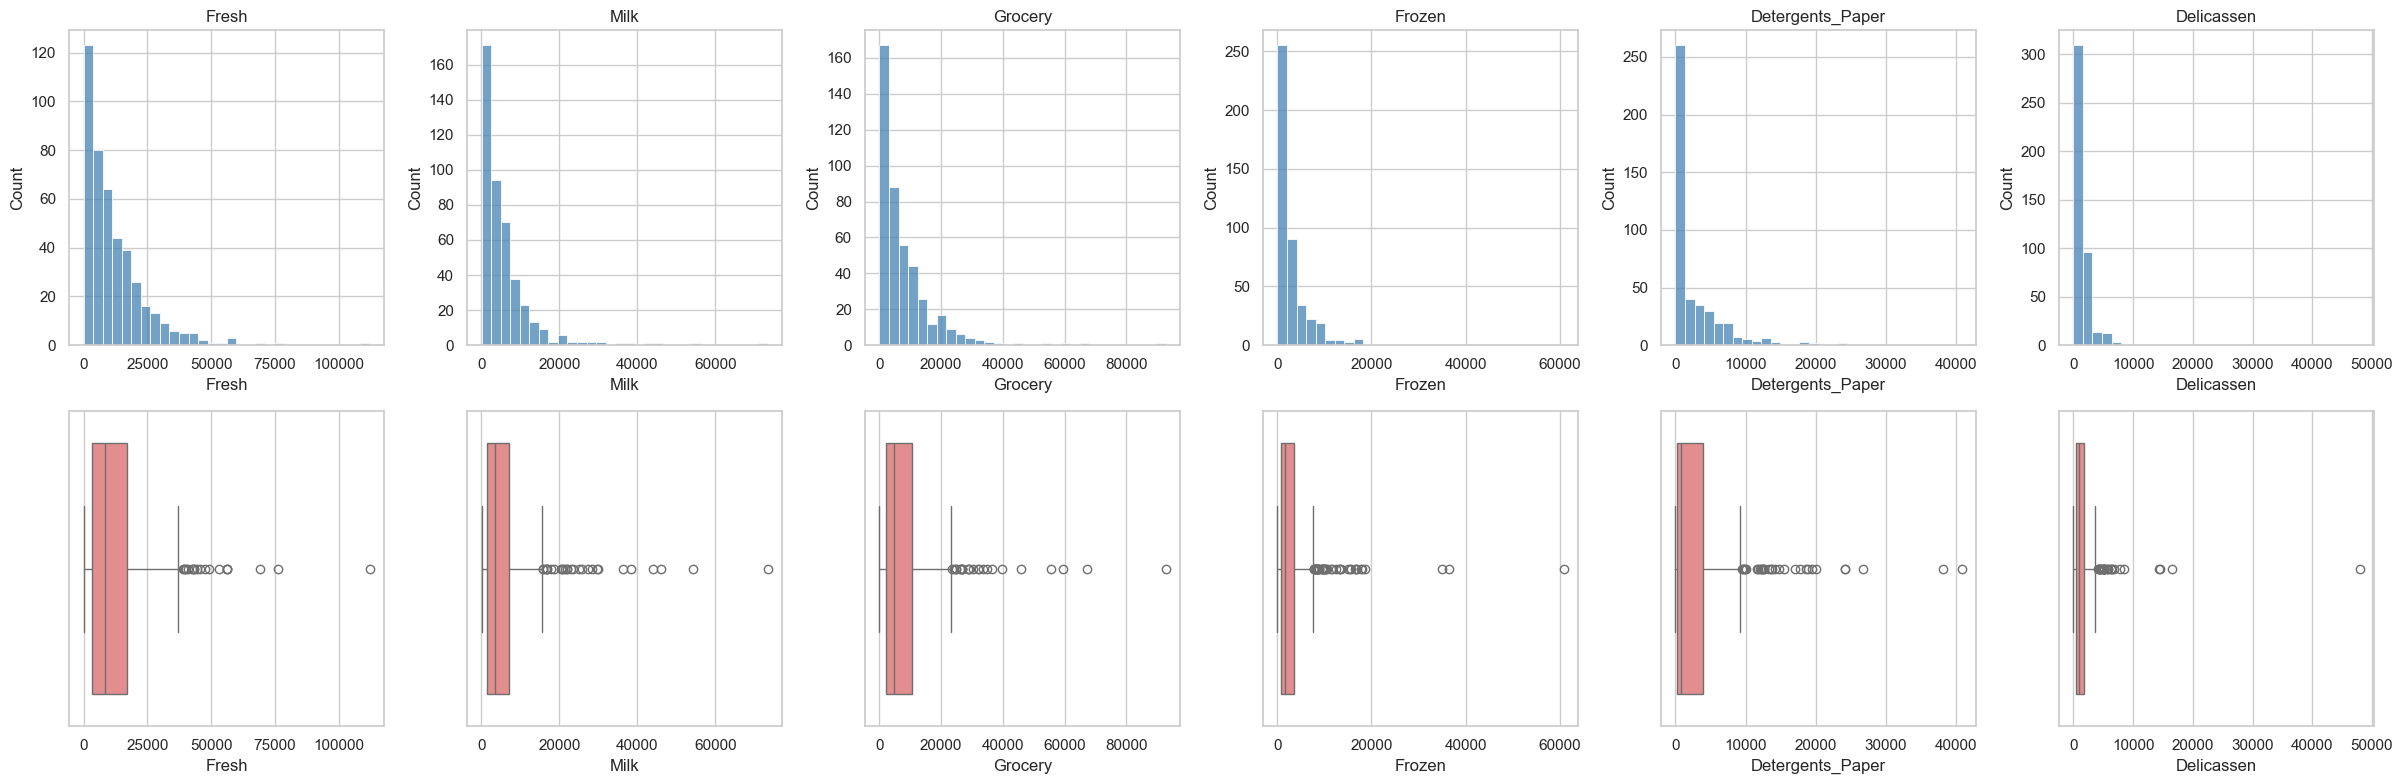

In [7]:
fig, axes = plt.subplots(2, 6, figsize=(24, 8))
for i, col in enumerate(spend_cols):
    sns.histplot(wholesale_df[col], bins=30, ax=axes[0, i], color="steelblue")
    axes[0, i].set_title(f"{col}")
    sns.boxplot(x=wholesale_df[col], ax=axes[1, i], color="lightcoral")
plt.tight_layout()
plt.show()

### Interpretation – Distributions
- All 6 spending columns are strongly right-skewed. Most clients spend small amounts, and a long tail of clients spends much more.
- The boxplots show many outliers in every category. Some are extreme: one client spends 112,151 m.u. on Fresh and another spends 47,943 m.u. on Delicassen, about 50 times the median.
- Some clients spend as little as 3 m.u. in a category, so they hardly buy it at all.
- DBSCAN and BIRCH both use distances, so without fixing this skew the few huge buyers would dominate. I will apply a log transform before scaling.

### 4.1 Correlation Between Spending Categories

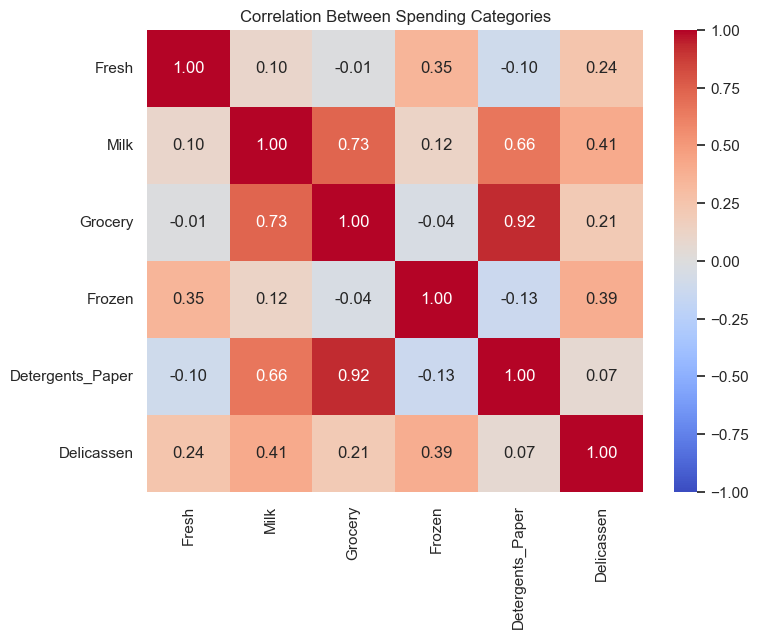

In [8]:
plt.figure(figsize=(8, 6))
sns.heatmap(wholesale_df[spend_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation Between Spending Categories")
plt.show()

### Interpretation – Correlation
- Grocery and Detergents_Paper are very strongly correlated (0.92), and Milk is also strongly linked to both (0.73 with Grocery and 0.66 with Detergents_Paper). Clients who buy a lot of one of these usually buy a lot of the others. This looks like a "retail shelf" basket of products that shops resell.
- Fresh and Frozen are only weakly related to each other (0.35) and barely related to Grocery or Detergents_Paper. This looks more like a "kitchen" basket, typical of hotels and restaurants.
- This suggests the clusters may follow the Horeca vs Retail split. I keep all 6 features, but because Grocery and Detergents_Paper carry almost the same information, that pattern will count a bit more in the distances.
Step 4: Preprocess (feature selection, log transform, scaling)

## 5. Preprocessing – Feature Selection, Log Transform and Scaling

In [9]:
X_spend = wholesale_df[spend_cols].copy()
X_log = np.log1p(X_spend)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_log)

print("Shape of features used for clustering:", X_scaled.shape)
display(pd.DataFrame(X_scaled, columns=spend_cols).describe().round(2))

Shape of features used for clustering: (440, 6)


,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
count,440.00,440.00,440.00,440.00,440.00,440.00
mean,0.00,-0.00,-0.00,0.00,-0.00,-0.00
std,1.00,1.00,1.00,1.00,1.00,1.00
min,-5.00,-3.79,-6.36,-3.16,-3.17,-4.09
25%,-0.47,-0.73,-0.69,-0.54,-0.73,-0.51
50%,0.21,0.07,0.02,0.02,-0.05,0.16
75%,0.68,0.70,0.75,0.68,0.87,0.65
max,1.97,2.86,2.70,2.90,2.24,3.18


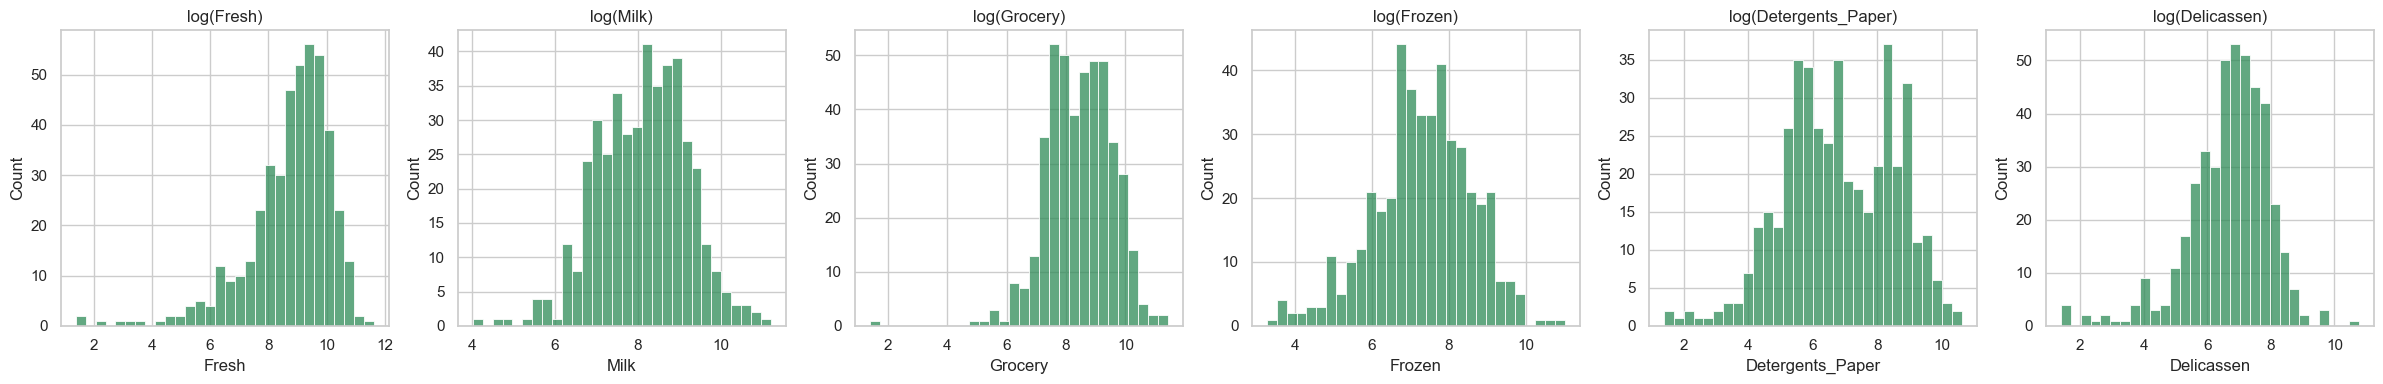

PCA explained variance: [0.441 0.272] | Total: 0.713


In [10]:
fig, axes = plt.subplots(1, 6, figsize=(24, 4))
for i, col in enumerate(spend_cols):
    sns.histplot(X_log[col], bins=30, ax=axes[i], color="seagreen")
    axes[i].set_title(f"log({col})")
plt.tight_layout()
plt.show()

pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)
print("PCA explained variance:", pca.explained_variance_ratio_.round(3),
      "| Total:", pca.explained_variance_ratio_.sum().round(3))

### Interpretation – Preprocessing
- I used only the 6 spending columns for clustering (440 clients × 6 features). I left out Channel and Region because they are category codes, but I kept them in the original table to compare with the clusters later.
- After the log transform, all 6 columns look much closer to a bell shape, so the very large buyers no longer dominate. After scaling, every column has a mean of 0 and a standard deviation of 1.
- The extreme values are now on the low side (for example, Grocery goes down to -6.36 and Fresh to -5.00). These are clients who spend almost nothing in a category, such as 3 m.u. The log transform spreads out very small values, so these clients now stand out and may be marked as noise by DBSCAN.
- log(Detergents_Paper) has two peaks (around 5.5 and 8). This suggests two different types of clients, probably shops that buy a lot of detergent and paper to resell, and hotels or restaurants that buy little.
- PCA with 2 components keeps 71.3% of the information (44.1% + 27.2%), so the 2D plots I use for visualizing the clusters are a fairly accurate view of the 6-dimensional data.

## 6. DBSCAN then ### 6.1 Choosing eps – k-distance Plot

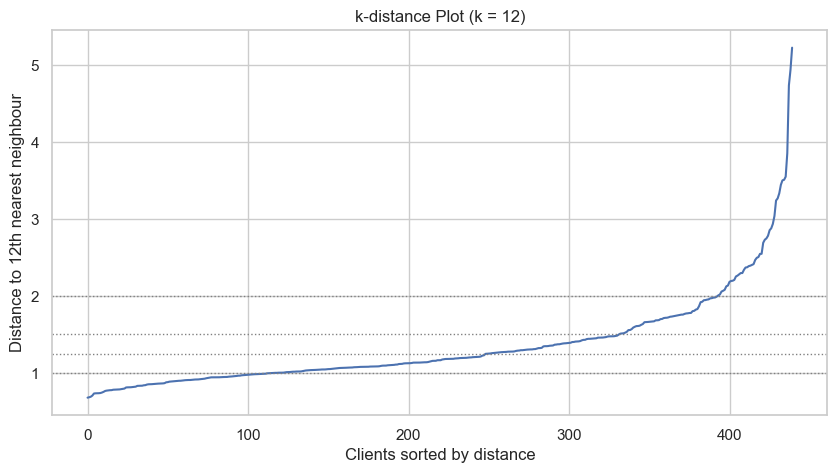

k-distance percentiles:
  50th percentile: 1.164
  75th percentile: 1.480
  90th percentile: 2.056
  95th percentile: 2.494
  98th percentile: 3.280


In [12]:
min_samples = 12

nn = NearestNeighbors(n_neighbors=min_samples)
nn.fit(X_scaled)
distances, _ = nn.kneighbors(X_scaled)
k_distances = np.sort(distances[:, -1])

plt.figure(figsize=(10, 5))
plt.plot(k_distances)
plt.title(f"k-distance Plot (k = {min_samples})")
plt.xlabel("Clients sorted by distance")
plt.ylabel(f"Distance to {min_samples}th nearest neighbour")
for y in [1.0, 1.25, 1.5, 2.0]:
    plt.axhline(y=y, color="grey", linestyle=":", linewidth=1)
plt.show()

print("k-distance percentiles:")
for q in [50, 75, 90, 95, 98]:
    print(f"  {q}th percentile: {np.percentile(k_distances, q):.3f}")

### Interpretation – k-distance Plot
- The plot shows, for every client, the distance to its 12th nearest neighbour, sorted from smallest to largest.
- For most clients this distance grows slowly, from about 0.7 to 2.0. Half of the clients have a 12th neighbour within 1.164, and 75% within 1.480. These clients are in dense areas.
- At about 2.0 (around the 90th percentile, 2.056) the curve bends sharply upward and rises above 5. The last 40 to 50 clients are much farther from everyone else, so they are in sparse areas and are likely outliers.
- I chose eps = 2.0 at this bend, with min_samples = 12 (2 × 6 features). Clients below the bend should belong to dense clusters, and clients above it should be labelled as noise. I expect about 10% of clients to be noise.

### 6.2 DBSCAN Results (eps = 2.0, min_samples = 12)

In [13]:
dbscan = DBSCAN(eps=2.0, min_samples=12)
db_labels = dbscan.fit_predict(X_scaled)

n_clusters_db = len(set(db_labels)) - (1 if -1 in db_labels else 0)
n_noise = (db_labels == -1).sum()
print(f"Clusters found: {n_clusters_db}")
print(f"Noise points: {n_noise} ({n_noise / len(db_labels) * 100:.1f}%)")
print("Cluster sizes:", pd.Series(db_labels).value_counts().sort_index().to_dict())

Clusters found: 1
Noise points: 17 (3.9%)
Cluster sizes: {-1: 17, 0: 423}


In [14]:
mask = db_labels != -1
if n_clusters_db >= 2:
    print(f"Silhouette (without noise): {silhouette_score(X_scaled[mask], db_labels[mask]):.4f}")

results_df = wholesale_df.copy()
results_df["dbscan"] = db_labels
results_df["Channel_name"] = results_df["Channel"].map(channel_names)
display(pd.crosstab(results_df["dbscan"], results_df["Channel_name"]))
display(results_df.groupby("dbscan")[spend_cols].median().round(0))

Channel_name,Horeca,Retail
dbscan,,
-1,13,4
0,285,138


,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
dbscan,,,,,,
-1,503.0,2616.0,7417.0,469.0,836.0,110.0
0,8635.0,3648.0,4740.0,1593.0,813.0,993.0


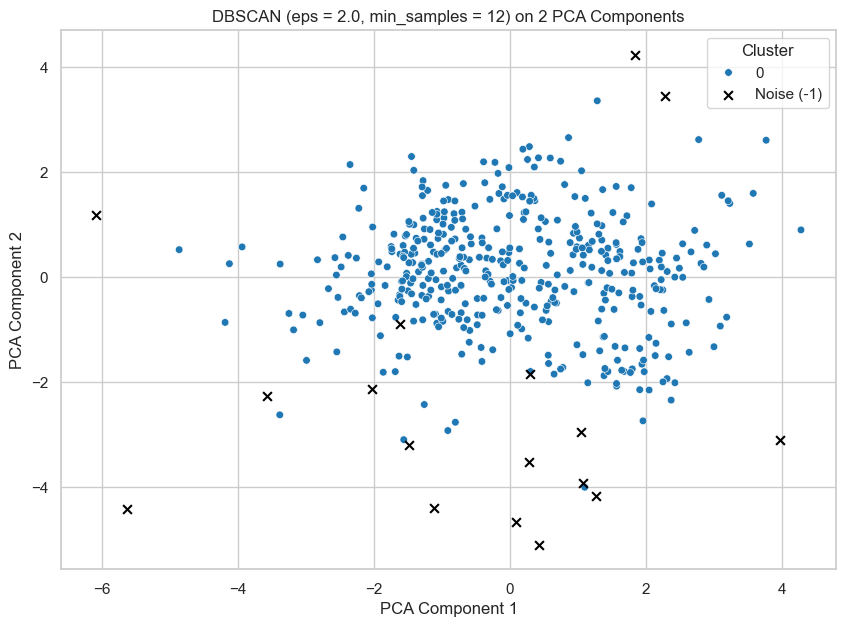

In [15]:
plt.figure(figsize=(10, 7))
sns.scatterplot(x=X_pca[mask, 0], y=X_pca[mask, 1], hue=db_labels[mask], palette="tab10", s=30)
plt.scatter(X_pca[~mask, 0], X_pca[~mask, 1], c="black", marker="x", s=40, label="Noise (-1)")
plt.title("DBSCAN (eps = 2.0, min_samples = 12) on 2 PCA Components")
plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.legend(title="Cluster")
plt.show()

### 6.3 DBSCAN Parameter Tuning – eps and min_samples

In [16]:
eps_values = [0.75, 1.0, 1.25, 1.5, 2.0, 2.5]
min_samples_values = [5, 8, 12, 20]
channel_true = wholesale_df["Channel"].values
tuning_rows = []

for eps in eps_values:
    for ms in min_samples_values:
        labels = DBSCAN(eps=eps, min_samples=ms).fit_predict(X_scaled)
        n_clu = len(set(labels)) - (1 if -1 in labels else 0)
        noise_pct = (labels == -1).mean() * 100
        m = labels != -1
        sil = silhouette_score(X_scaled[m], labels[m]) if n_clu >= 2 else np.nan
        tuning_rows.append({"eps": eps, "min_samples": ms, "clusters": n_clu,
                            "noise_%": round(noise_pct, 1),
                            "silhouette": round(sil, 3) if not np.isnan(sil) else np.nan,
                            "ARI_vs_Channel": round(adjusted_rand_score(channel_true, labels), 3)})

db_tuning = pd.DataFrame(tuning_rows)
print(db_tuning.to_string(index=False))

 eps  min_samples  clusters  noise_%  silhouette  ARI_vs_Channel
0.75            5         4     63.9      -0.066           0.033
0.75            8         4     78.0       0.371           0.095
0.75           12         1     93.0         NaN           0.103
0.75           20         0    100.0         NaN           0.000
1.00            5         1     28.2         NaN          -0.019
1.00            8         2     33.2       0.245           0.018
1.00           12         1     41.6         NaN          -0.003
1.00           20         2     58.9       0.473           0.108
1.25            5         1     15.9         NaN          -0.017
1.25            8         1     18.0         NaN          -0.012
1.25           12         1     20.0         NaN           0.005
1.25           20         1     26.8         NaN           0.016
1.50            5         1      9.3         NaN          -0.028
1.50            8         1     10.2         NaN          -0.024
1.50           12        

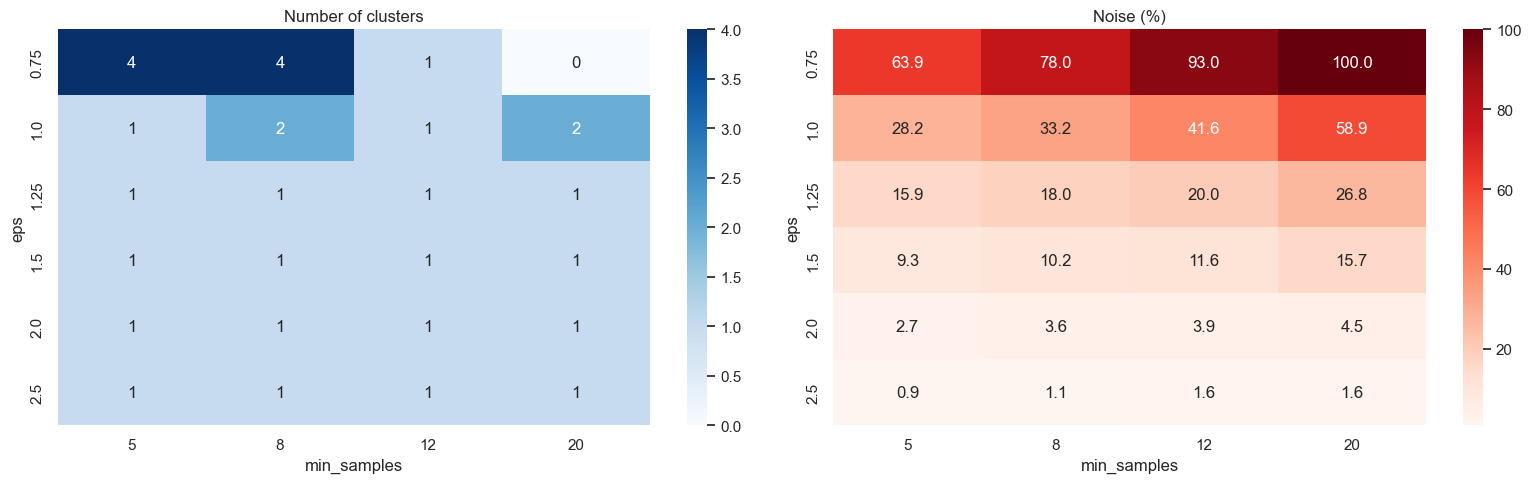

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
sns.heatmap(db_tuning.pivot(index="eps", columns="min_samples", values="clusters"),
            annot=True, fmt="d", cmap="Blues", ax=axes[0])
axes[0].set_title("Number of clusters")
sns.heatmap(db_tuning.pivot(index="eps", columns="min_samples", values="noise_%"),
            annot=True, fmt=".1f", cmap="Reds", ax=axes[1])
axes[1].set_title("Noise (%)")
plt.tight_layout()
plt.show()

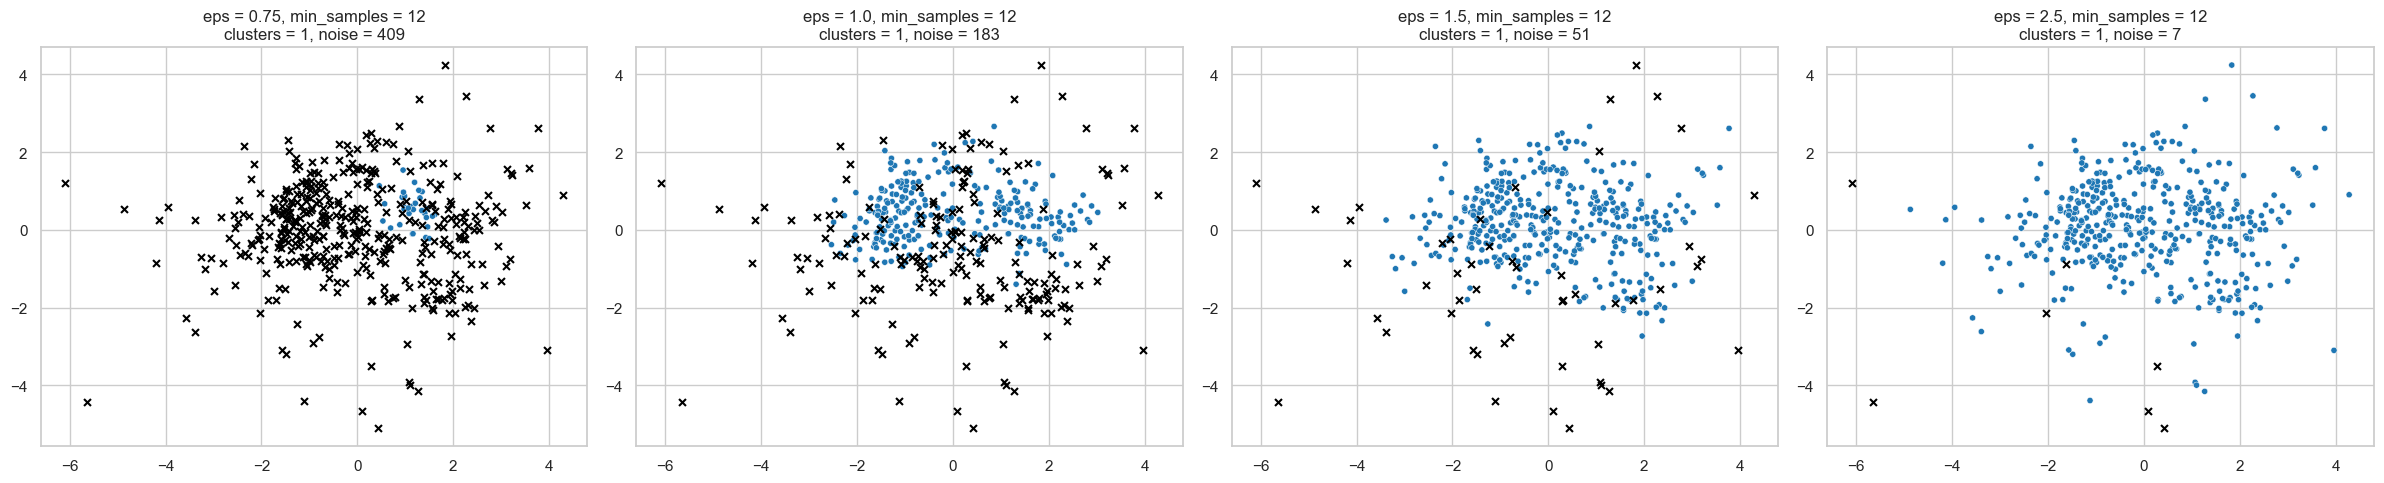

In [18]:
fig, axes = plt.subplots(1, 4, figsize=(24, 5))
for ax, eps in zip(axes, [0.75, 1.0, 1.5, 2.5]):
    labels = DBSCAN(eps=eps, min_samples=12).fit_predict(X_scaled)
    m = labels != -1
    sns.scatterplot(x=X_pca[m, 0], y=X_pca[m, 1], hue=labels[m], palette="tab10", s=20, ax=ax, legend=False)
    ax.scatter(X_pca[~m, 0], X_pca[~m, 1], c="black", marker="x", s=25)
    ax.set_title(f"eps = {eps}, min_samples = 12\nclusters = {len(set(labels[m]))}, noise = {(~m).sum()}")
plt.tight_layout()
plt.show()

### Interpretation – DBSCAN Parameter Tuning
I tested 24 combinations of eps (0.75 to 2.5) and min_samples (5 to 20).

Effect of eps:
- eps has the biggest effect. With min_samples = 12, the share of noise drops from 93.0% (eps = 0.75) to 41.6% (1.0), 11.6% (1.5), 3.9% (2.0) and 1.6% (2.5).
- A small eps means each client needs neighbours very close by, so most clients are labelled noise. A large eps makes the neighbourhood bigger, so almost every client joins the cluster.
- The scatter plots show this clearly: at eps = 0.75 almost all points are noise (black x), and as eps grows the single cluster spreads from the dense centre outwards.

Effect of min_samples:
- A higher min_samples makes DBSCAN stricter, so the noise goes up. For example, at eps = 1.0 the noise rises from 28.2% (min_samples = 5) to 58.9% (min_samples = 20).

Number of clusters:
- 20 of the 24 combinations found only 1 cluster (or 0 at the strictest setting).
- More than 1 cluster only appeared with a small eps, and then most clients were labelled noise (4 clusters with 64% to 78% noise, 2 clusters with 33% to 59% noise). These results are not useful because they ignore most of the data.
- The highest silhouette score (0.473 at eps = 1.0, min_samples = 20) is misleading, because it is calculated without the 58.9% of clients marked as noise.
- The ARI (Adjusted Rand Index) against Channel is never higher than 0.108, so DBSCAN never separates Horeca from Retail.

Conclusion: the clients form one continuous dense cloud with no empty gaps between groups, so DBSCAN cannot split them into meaningful segments. I keep eps = 2.0 and min_samples = 12 as my final setting, because it gives one stable cluster and a small group of real outliers (3.9%). In this dataset DBSCAN is most useful for finding unusual clients, not for segmentation.

## 7. BIRCH then ### 7.1 BIRCH with Different n_clusters

In [19]:
birch_rows = []
birch_labels = {}

for k in range(2, 9):
    birch = Birch(n_clusters=k, threshold=0.5, branching_factor=50)
    labels = birch.fit_predict(X_scaled)
    birch_labels[k] = labels
    birch_rows.append({"n_clusters": k,
                       "subclusters": len(birch.subcluster_centers_),
                       "sizes": np.bincount(labels).tolist(),
                       "silhouette": round(silhouette_score(X_scaled, labels), 4),
                       "ARI_vs_Channel": round(adjusted_rand_score(channel_true, labels), 4)})

birch_tuning = pd.DataFrame(birch_rows)
print(birch_tuning.to_string(index=False))

 n_clusters  subclusters                            sizes  silhouette  ARI_vs_Channel
          2          258                       [235, 205]      0.2219          0.3007
          3          258                  [106, 205, 129]      0.2157          0.3151
          4          258               [88, 205, 129, 18]      0.2197          0.3279
          5          258           [205, 18, 129, 41, 47]      0.2090          0.3318
          6          258       [129, 18, 149, 41, 47, 56]      0.1448          0.1895
          7          258    [18, 41, 149, 89, 47, 56, 40]      0.1413          0.2291
          8          258 [149, 41, 56, 89, 47, 6, 40, 12]      0.1478          0.2287


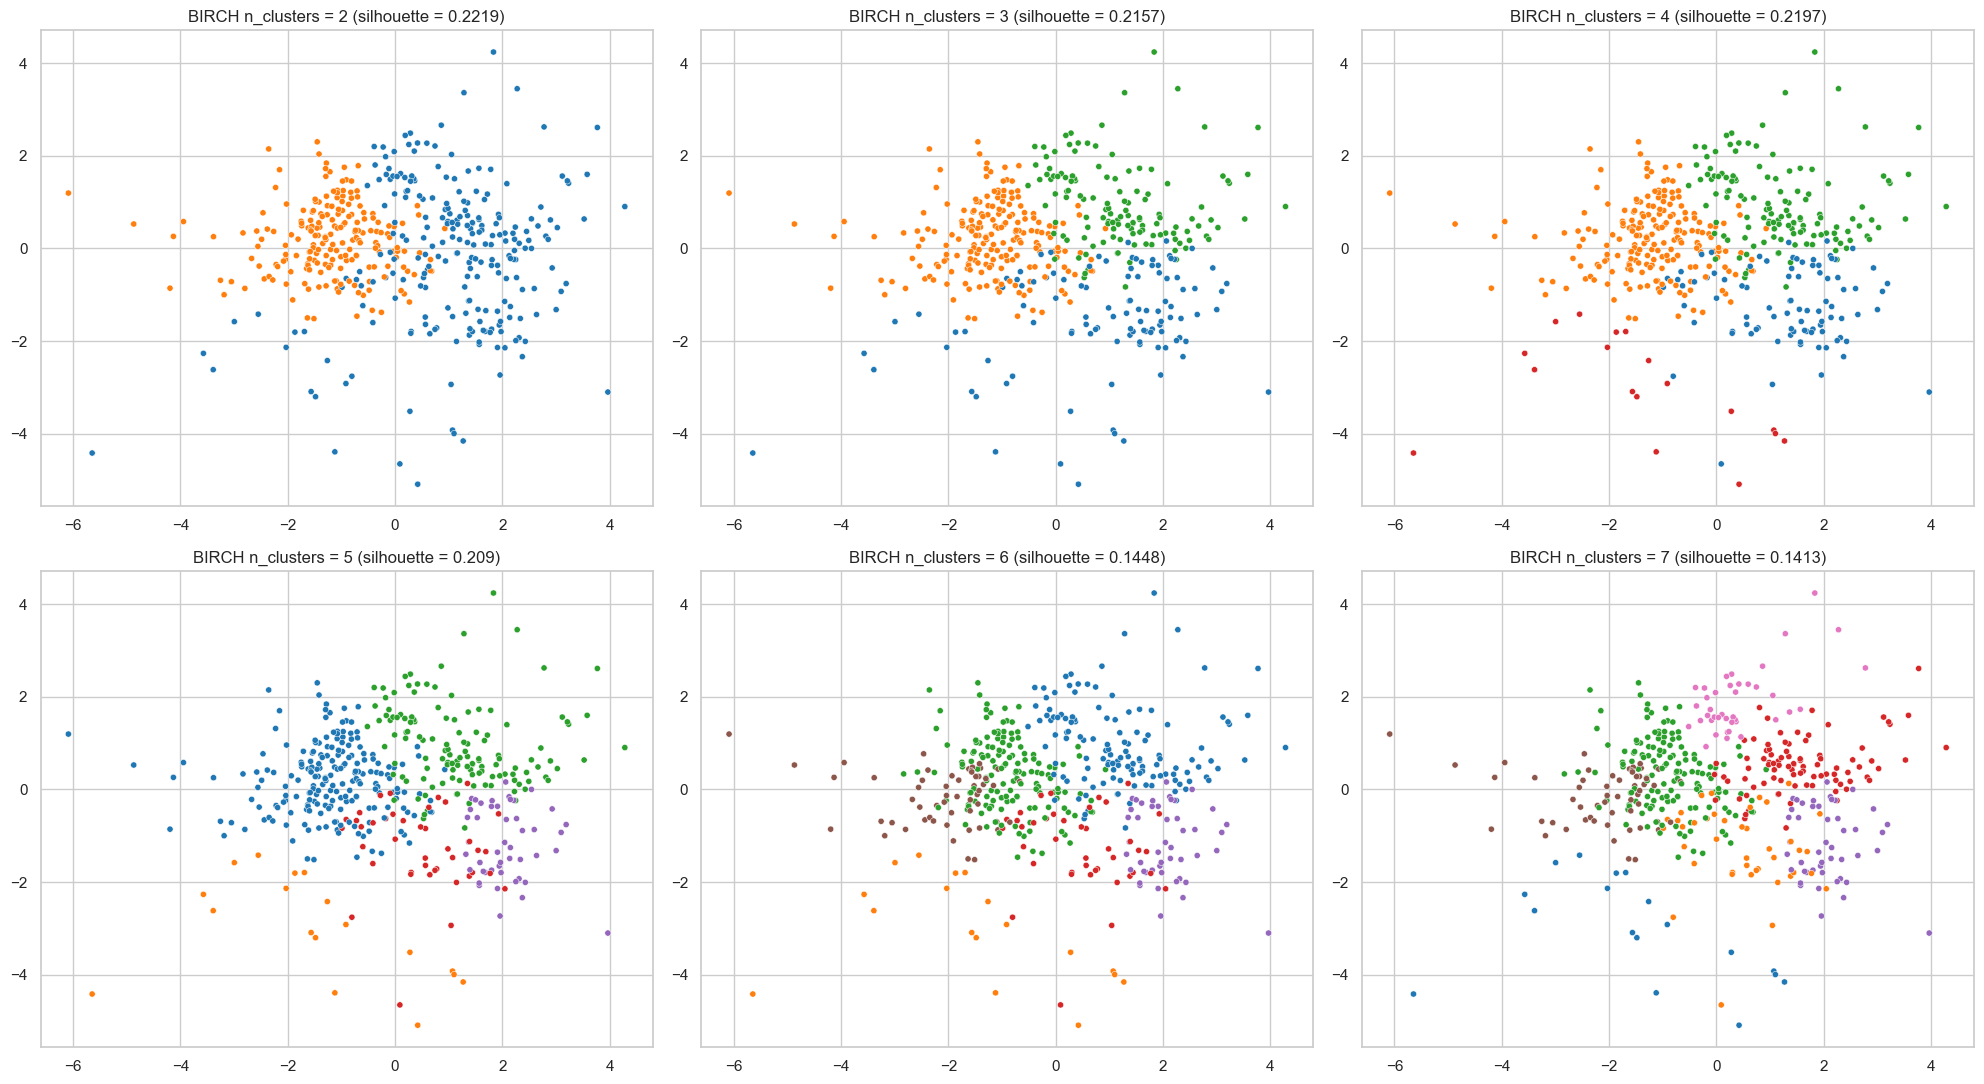

In [20]:
fig, axes = plt.subplots(2, 3, figsize=(20, 11))
for ax, k in zip(axes.flatten(), range(2, 8)):
    sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=birch_labels[k], palette="tab10", s=20, ax=ax, legend=False)
    sil = birch_tuning.loc[birch_tuning["n_clusters"] == k, "silhouette"].values[0]
    ax.set_title(f"BIRCH n_clusters = {k} (silhouette = {sil})")
plt.tight_layout()
plt.show()

### 7.2 Effect of the BIRCH threshold

In [21]:
thr_rows = []
for thr in [0.3, 0.5, 1.0, 1.5, 2.0]:
    b_none = Birch(n_clusters=None, threshold=thr).fit(X_scaled)
    b_2 = Birch(n_clusters=2, threshold=thr)
    lab_2 = b_2.fit_predict(X_scaled)
    thr_rows.append({"threshold": thr,
                     "subclusters (n_clusters=None)": len(b_none.subcluster_centers_),
                     "silhouette (n_clusters=2)": round(silhouette_score(X_scaled, lab_2), 4),
                     "ARI_vs_Channel (n_clusters=2)": round(adjusted_rand_score(channel_true, lab_2), 4)})
print(pd.DataFrame(thr_rows).to_string(index=False))

 threshold  subclusters (n_clusters=None)  silhouette (n_clusters=2)  ARI_vs_Channel (n_clusters=2)
       0.3                            381                     0.1982                         0.0790
       0.5                            258                     0.2219                         0.3007
       1.0                             81                     0.3786                        -0.0029
       1.5                             30                     0.2163                        -0.0574
       2.0                             12                     0.3460                        -0.0308


### Interpretation – Effect of the BIRCH Threshold
- The threshold controls how much BIRCH compresses the data in its CF tree. As the threshold increases from 0.3 to 2.0, the number of subclusters drops from 381 to 258, 81, 30 and finally 12. A small threshold keeps a very detailed summary (381 subclusters for 440 clients is almost no compression), while a large threshold groups many clients into a few big subclusters.
- The threshold also changes the final 2 clusters a lot. The ARI against Channel is 0.30 at threshold 0.5, but drops to about 0 (between -0.06 and 0.08) for all other values. With large subclusters, the differences between Horeca-like and Retail-like clients get blended together before the final clustering step.
- The silhouette score jumps around without a clear pattern (0.198, 0.222, 0.379, 0.216, 0.346). The higher scores at thresholds 1.0 and 2.0, combined with an ARI near 0, likely mean that BIRCH separated a small group of unusual clients from everyone else. This can give a high silhouette score without creating useful segments.
- I keep threshold = 0.5, because it gives the most meaningful split of the clients. This experiment shows that BIRCH results are very sensitive to the threshold, which is one of its main limitations.

In [22]:
birch_final = Birch(n_clusters=2, threshold=0.5, branching_factor=50)
birch_final_labels = birch_final.fit_predict(X_scaled)
results_df["birch"] = birch_final_labels

print("BIRCH vs Channel:")
display(pd.crosstab(results_df["birch"], results_df["Channel_name"]))
print("Median spending (m.u.) per BIRCH cluster:")
display(results_df.groupby("birch")[spend_cols].median().round(0))

BIRCH vs Channel:


Channel_name,Horeca,Retail
birch,,
0,96,139
1,202,3


Median spending (m.u.) per BIRCH cluster:


,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
birch,,,,,,
0,7588.0,6343.0,9794.0,1069.0,3620.0,1265.0
1,9203.0,1801.0,2223.0,2208.0,273.0,778.0


In [24]:
results_df["birch_k4"] = birch_labels[4]
small_group = results_df["birch_k4"].value_counts().idxmin()
print(f"\nBIRCH k=4 small cluster (label {small_group}) vs DBSCAN noise:")
display(pd.crosstab(results_df["birch_k4"] == small_group, results_df["dbscan"] == -1,
                    rownames=["In BIRCH small cluster"], colnames=["DBSCAN noise"]))


BIRCH k=4 small cluster (label 3) vs DBSCAN noise:


DBSCAN noise,False,True
In BIRCH small cluster,,
False,414,8
True,9,9


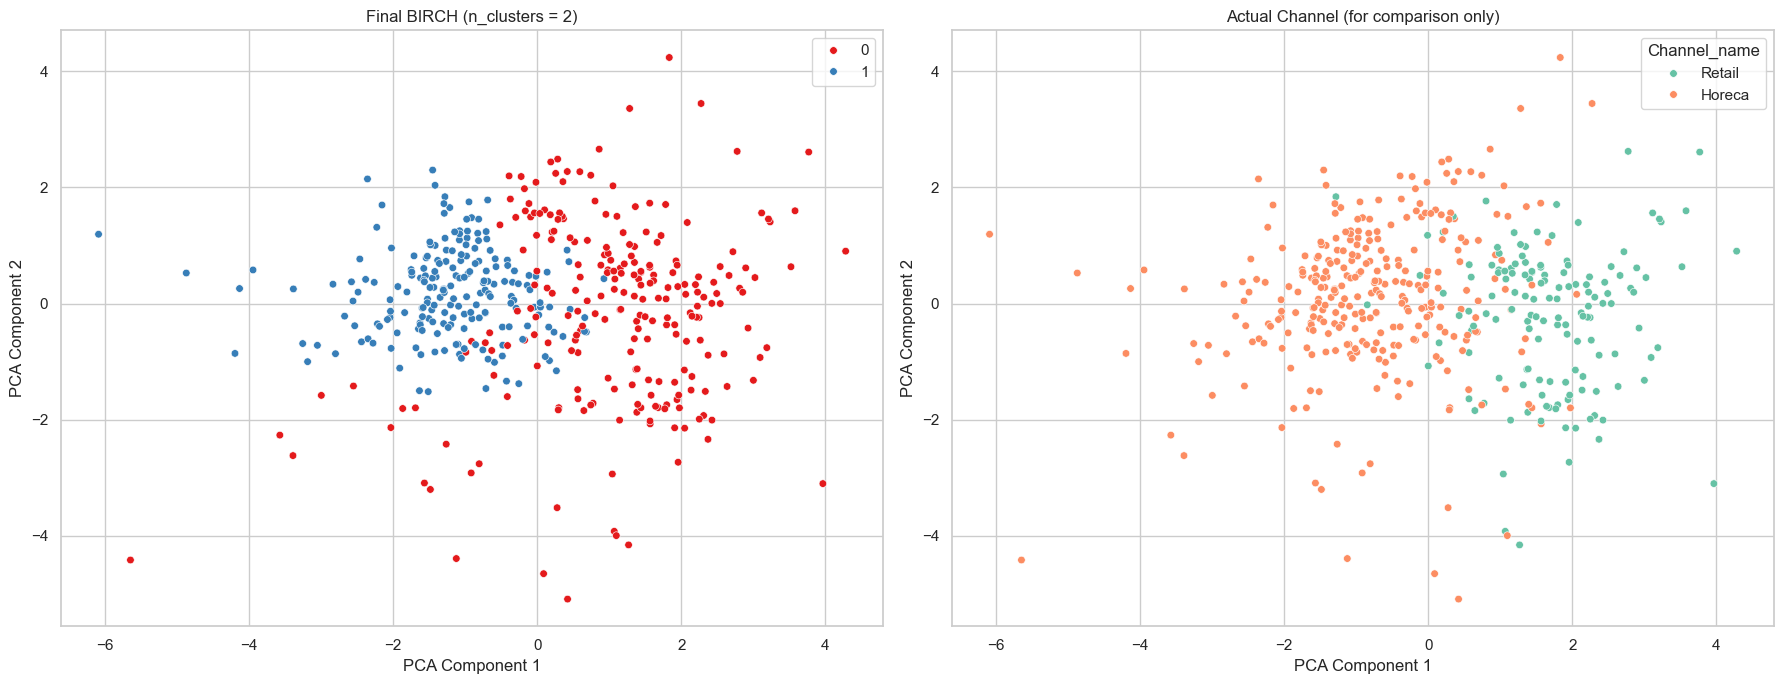

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(18, 7))
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=birch_final_labels, palette="Set1", s=30, ax=axes[0])
axes[0].set_title("Final BIRCH (n_clusters = 2)")
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=results_df["Channel_name"], palette="Set2", s=30, ax=axes[1])
axes[1].set_title("Actual Channel (for comparison only)")
for ax in axes:
    ax.set_xlabel("PCA Component 1")
    ax.set_ylabel("PCA Component 2")
plt.tight_layout()
plt.show()

### Interpretation – Final BIRCH Model (n_clusters = 2)
BIRCH split the clients into two groups with clearly different buying patterns:
- Cluster 1 – Kitchen buyers (205 clients): 202 of them are Horeca (98.5%). They spend the most on Fresh (median 9,203 m.u.) and Frozen (2,208 m.u.), and very little on Detergents_Paper (273 m.u.), Grocery (2,223 m.u.) and Milk (1,801 m.u.). This fits hotels, restaurants and cafés that buy ingredients to cook with.
- Cluster 0 – Retail-shelf buyers (235 clients): this group contains 139 of the 142 Retail clients (98%) plus 96 Horeca clients. They spend much more on Grocery (9,794 m.u.), Milk (6,343 m.u.) and Detergents_Paper (3,620 m.u., about 13 times more than cluster 1). These are products that shops resell. The Horeca clients in this group probably buy like small shops, for example cafés that sell packaged goods.

Even though I never used the Channel column to build the clusters, BIRCH separated almost all Retail clients from a nearly pure Horeca group, which is why its ARI against Channel (0.30) is much higher than DBSCAN's. The side-by-side plot shows this too: the BIRCH clusters (left) look very similar to the real channels (right).

Comparison with DBSCAN's outliers:
- 9 of the 17 DBSCAN noise clients are also in the small 18-client group that BIRCH created with n_clusters = 4. So about half of the unusual low-spending clients were found by both methods, even though DBSCAN uses density and BIRCH uses a CF tree with hierarchical grouping.

## 8. Discussion

### Impact of parameter values

DBSCAN (eps and min_samples):
- eps had the biggest effect. With min_samples = 12, the noise dropped from 93.0% (eps = 0.75) to 3.9% (eps = 2.0) and 1.6% (eps = 2.5). A small eps labels most clients as noise, and a large eps puts almost everyone into one cluster.
- A higher min_samples made DBSCAN stricter and increased the noise (at eps = 1.0, from 28.2% with min_samples = 5 to 58.9% with min_samples = 20).
- In 20 of the 24 combinations DBSCAN found only one cluster. It found more clusters only when it labelled 33% to 78% of clients as noise, which is not useful.
- The k-distance plot was a good way to choose eps. Its bend at about 2.0 gave a stable result with a small, meaningful set of outliers.

BIRCH (n_clusters and threshold):
- With n_clusters from 2 to 5, the silhouette score stayed between 0.209 and 0.222 and the ARI against Channel between 0.30 and 0.33. From 6 clusters, the silhouette dropped to about 0.14.
- The clusters were nested: increasing n_clusters only split one existing group, and the 205-client Horeca group stayed the same from 2 to 5 clusters. This is because BIRCH's last step is hierarchical clustering.
- The threshold changed the results a lot. It reduced the CF tree from 381 subclusters (0.3) to 12 (2.0), and only the default threshold of 0.5 kept the Horeca vs Retail pattern (ARI 0.30). With larger thresholds the ARI dropped to about 0.

### Strengths and limitations based on my results

DBSCAN strengths:
- It found outliers automatically: 17 clients (3.9%) with a very unusual spending pattern (almost no fresh, frozen or deli products).
- It did not need the number of clusters in advance.

DBSCAN limitations:
- It could not split this dataset into segments, because the clients form one continuous dense cloud with no low-density gaps between groups.
- It was very sensitive to eps and min_samples, and small changes moved the noise from about 2% to over 90%.
- Silhouette scores can be misleading with DBSCAN, because they are calculated without the noise points.

BIRCH strengths:
- It found a meaningful business split: a 205-client group that is 98.5% Horeca and a group with 98% of all Retail clients, with clearly different spending patterns.
- It is very fast and memory-efficient, because it works on a compact summary (the CF tree) instead of every point. This matters more for very large datasets than for 440 clients.
- Its nested results let me look at the data at different levels of detail (2, 4 or 5 clusters).

BIRCH limitations:
- It needs n_clusters (and a good threshold) chosen by the user.
- It is very sensitive to the threshold: the same n_clusters gave completely different clusters depending on the threshold.
- It has no noise label, so outliers are forced into a cluster unless a larger n_clusters creates a small group for them.
- The results can also depend on the order of the data, because the CF tree is built in a single pass.

Overall, BIRCH was better for customer segmentation on this dataset, while DBSCAN was better for finding unusual clients.

## 9. Summary of Findings

### Dataset and algorithms
I used the UCI Wholesale Customers dataset, which contains the annual spending of 440 clients of a Portuguese wholesale distributor across 6 product categories (Fresh, Milk, Grocery, Frozen, Detergents_Paper and Delicassen), plus their channel (Horeca or Retail) and region. I compared two clustering algorithms: DBSCAN, which groups dense areas and labels isolated points as noise, and BIRCH, which summarizes the data in a CF tree and then groups the summaries into a chosen number of clusters.

### Preprocessing
- I used only the 6 spending columns for clustering. Channel and Region are category codes, so I kept them aside and used Channel only to check the results.
- The data had no missing values or duplicates.
- All spending columns were strongly right-skewed with extreme outliers, so I applied a log transform and then standardized every column.
- I used PCA (2 components, 71.3% of the information) only to visualize the clusters.

### Results
- DBSCAN (eps = 2.0, min_samples = 12, chosen with a k-distance plot) found one cluster of 423 clients and 17 noise clients (3.9%). The noise clients spend very little on Fresh, Frozen and Delicassen but more on Grocery.
- BIRCH (n_clusters = 2, threshold = 0.5) found a "kitchen buyers" group of 205 clients (98.5% Horeca) that spends most on Fresh and Frozen, and a "retail-shelf buyers" group of 235 clients (with 98% of all Retail clients) that spends most on Grocery, Milk and Detergents_Paper. Its ARI against Channel was 0.30, compared with at most 0.108 for DBSCAN.
- About half of DBSCAN's outliers (9 of 17) were also in a small 18-client group that BIRCH created with 4 clusters.

### Impact of parameter tuning
- For DBSCAN, eps controlled the amount of noise (from 93% to under 2%), and higher min_samples increased the noise. Almost all settings gave only one cluster.
- For BIRCH, n_clusters from 2 to 5 gave similar quality with nested splits. The threshold strongly changed the final clusters, and only 0.5 kept the Horeca vs Retail pattern.

### Strengths and limitations
DBSCAN was good at detecting outliers without needing the number of clusters, but it could not segment data that forms one continuous cloud, and it was very sensitive to its parameters. BIRCH found a clear and useful business segmentation and is efficient for large data, but it needs n_clusters, has no noise label and is very sensitive to the threshold. For this dataset, I would use BIRCH to segment the distributor's clients and DBSCAN to flag unusual clients for a closer look.